In [ ]:
!pip install -q torch torchvision transformers datasets matplotlib numpy pillow

In [2]:
import time
from collections.abc import Callable
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from datasets import load_dataset
from PIL import Image
from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor

warnings.filterwarnings("ignore")

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
MODEL_NAME = "nvidia/segformer-b0-finetuned-ade-512-512"
DATASET_NAME = "merve/scene_parse_150"
IMAGE_SIZE = 160
NUM_TRAIN, NUM_EVAL = 1500, 300
IGNORE_INDEX = 255
SEED = 0
torch.manual_seed(SEED)
print(f"DEVICE = {DEVICE}")

DEVICE = mps


# Image Segmentation

Semantic segmentation assigns a class to every pixel. The difficulty is a tension inside the
network: recognising *what* a region is needs a large receptive field, which a CNN gets by
downsampling, while saying *where* its boundary is needs full resolution. Two designs resolve it:

| Model | Encoder | How resolution comes back | Year |
|---|---|---|---|
| FCN | CNN, stride 32 | upsample the coarse logits (blurry edges) | 2015 |
| **U-Net** | CNN, stride 8–16 | symmetric decoder; **skip connections** concatenate encoder maps at each scale | 2015 |
| DeepLab v3+ | dilated CNN | atrous convolutions keep stride 8; light decoder | 2018 |
| **SegFormer** | hierarchical transformer (MiT), strides 4–32 | every stage projected to one width, upsampled to 1/4 and fused by an **all-MLP decoder** | 2021 |
| Mask2Former, SAM-family | transformer | per-query masks instead of per-pixel classes | 2022– |

A U-Net is trained from scratch and SegFormer-B0's decoder is rebuilt from its released weights,
both on real ADE20K scenes and scored with the same mIoU.

---

# 1) Data: ADE20K Scenes

ADE20K labels indoor and outdoor scenes with 150 classes; label 0 means "unlabelled". Training a
150-way segmenter from scratch takes days, so the task is narrowed to the **nine most frequent
stuff and thing classes**. Every other pixel is set to `IGNORE_INDEX` and contributes neither to
the loss nor to the metric. Images and masks are resized and centre-cropped to 160 × 160 (masks
with nearest-neighbour interpolation, so labels are never blended). The 2,000 validation images
are split into 1,500 for training and 300 for evaluation.

In [3]:
# ADE20K class ids (0-based, after removing "unlabelled") kept for the narrowed task
KEPT = {
    0: "wall",
    1: "building",
    2: "sky",
    3: "floor",
    4: "tree",
    5: "ceiling",
    6: "road",
    9: "grass",
    12: "person",
}
CLASS_NAMES = list(KEPT.values())
NUM_CLASSES = len(KEPT)
# lookup table: ADE annotation value (0 = unlabelled, 1..150) -> 0..8 or IGNORE_INDEX
ADE_TO_TASK = torch.full((256,), IGNORE_INDEX, dtype=torch.long)
for task_id, ade_id in enumerate(KEPT):
    ADE_TO_TASK[ade_id + 1] = task_id


def center_crop(img: Image.Image, interp: TF.InterpolationMode) -> torch.Tensor:
    """PIL image -> (C, IMAGE_SIZE, IMAGE_SIZE) uint8 tensor."""
    img = TF.resize(img, IMAGE_SIZE, interpolation=interp)
    return TF.pil_to_tensor(TF.center_crop(img, IMAGE_SIZE))


start = time.time()
ade = load_dataset(
    DATASET_NAME,
    data_files={"validation": "data/validation-*.parquet"},
    split="validation",
    verification_mode="no_checks",
)
rows = range(NUM_TRAIN + NUM_EVAL)
images = torch.stack(
    [
        center_crop(ade[i]["image"].convert("RGB"), TF.InterpolationMode.BILINEAR)
        for i in rows
    ]
)
masks = torch.stack(
    [center_crop(ade[i]["annotation"], TF.InterpolationMode.NEAREST)[0] for i in rows]
)
masks = ADE_TO_TASK[masks.long()]
train_images, eval_images = images[:NUM_TRAIN], images[NUM_TRAIN:]
train_masks, eval_masks = masks[:NUM_TRAIN], masks[NUM_TRAIN:]
print(
    f"images {tuple(images.shape)} uint8 | masks {tuple(masks.shape)} | "
    f"{time.time() - start:.0f} s"
)
labelled = masks[masks != IGNORE_INDEX]
share = torch.bincount(labelled, minlength=NUM_CLASSES).float() / labelled.numel()
print(f"labelled pixels: {labelled.numel() / masks.numel():.0%}")
print(" ".join(f"{n} {s:.0%}" for n, s in zip(CLASS_NAMES, share.tolist())))

images (1800, 3, 160, 160) uint8 | masks (1800, 160, 160) | 12 s


labelled pixels: 57%
wall 26% building 19% sky 16% floor 11% tree 8% ceiling 7% road 7% grass 3% person 4%


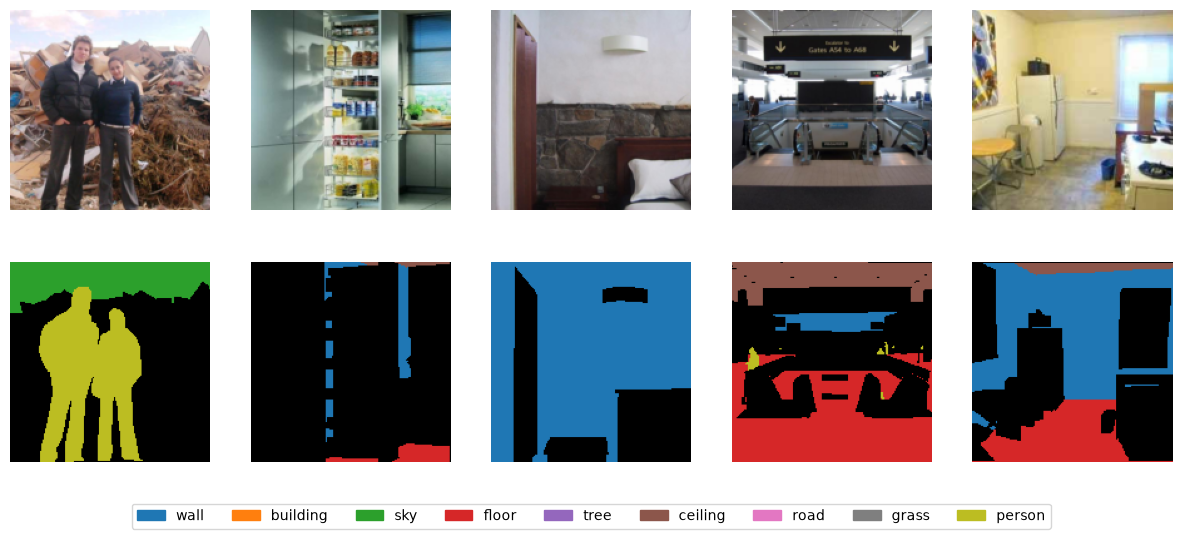

In [4]:
def show_masks(mask: torch.Tensor) -> np.ndarray:
    """(H, W) task labels -> (H, W, 3) colours, ignored pixels black."""
    palette = (plt.cm.tab10(np.arange(NUM_CLASSES))[:, :3] * 255).astype(np.uint8)
    out = np.zeros((*mask.shape, 3), dtype=np.uint8)
    valid = mask != IGNORE_INDEX
    out[valid.numpy()] = palette[mask[valid].numpy()]
    return out


fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for col in range(5):
    axes[0, col].imshow(train_images[col].permute(1, 2, 0))
    axes[1, col].imshow(show_masks(train_masks[col]))
    axes[0, col].axis("off")
    axes[1, col].axis("off")
handles = [
    plt.Rectangle((0, 0), 1, 1, color=plt.cm.tab10(k)) for k in range(NUM_CLASSES)
]
fig.legend(handles, CLASS_NAMES, loc="lower center", ncol=NUM_CLASSES)
plt.show()

# 2) The Math

**Loss.** The network outputs logits $z \in \mathbb{R}^{K \times H \times W}$. With labels
$y_{hw} \in \{0, \dots, K-1\} \cup \{\varnothing\}$ and $\Omega$ the set of labelled pixels,

$$\mathcal{L} = -\frac{1}{|\Omega|} \sum_{(h, w) \in \Omega} \log \operatorname{softmax}(z_{:,hw})_{y_{hw}}.$$

`F.cross_entropy(logits, labels, ignore_index=255)` implements exactly this on
`(batch_num, K, H, W)` logits and `(batch_num, H, W)` labels.

**Metric.** Accumulate a $K \times K$ confusion matrix $C_{ij} = \#\{\text{pixels with label } i
\text{ predicted } j\}$ over the whole evaluation set, then

$$\text{IoU}_k = \frac{C_{kk}}{\sum_j C_{kj} + \sum_i C_{ik} - C_{kk}}, \qquad
\text{mIoU} = \frac{1}{K} \sum_k \text{IoU}_k.$$

Summing the matrix over the dataset before dividing (not averaging per-image IoUs) is the
standard protocol: per-image IoU is undefined for classes absent from an image and
over-weights small images. Pixel accuracy, $\sum_k C_{kk} / \sum_{ij} C_{ij}$, is dominated by
large classes like wall and sky, which is why mIoU is the headline number.

In [5]:
def confusion_matrix(
    preds: torch.Tensor, labels: torch.Tensor, num_classes: int
) -> torch.Tensor:
    """preds, labels (...) -> (num_classes, num_classes) counts; ignored labels
    skipped.
    """
    valid = labels != IGNORE_INDEX
    # each (label, pred) pair -> one flat bin; predictions outside 0..K-1 count as wrong
    preds = preds[valid].clamp(0, num_classes)
    flat = labels[valid] * (num_classes + 1) + preds
    counts = torch.bincount(flat.cpu(), minlength=num_classes * (num_classes + 1))
    return counts.reshape(num_classes, num_classes + 1)[:, :num_classes]


def miou(conf: torch.Tensor) -> tuple[float, torch.Tensor]:
    """Confusion matrix (K, K) -> (mIoU, per-class IoU (K,))."""
    tp = conf.diag().float()
    union = conf.sum(1).float() + conf.sum(0).float() - tp
    iou = tp / union.clamp(min=1)
    return iou.mean().item(), iou


# 2 x 2 image, labels [[0, 1], [1, IGNORE]], prediction [[0, 1], [0, 1]]
toy_labels = torch.tensor([[0, 1], [1, IGNORE_INDEX]])
toy_preds = torch.tensor([[0, 1], [0, 1]])
toy_conf = confusion_matrix(toy_preds, toy_labels, 2)
print("confusion:", toy_conf.tolist())
print("IoU per class:", miou(toy_conf)[1].tolist(), "(class 0: 1/2, class 1: 1/2)")

confusion: [[1, 0], [1, 1]]
IoU per class: [0.5, 0.5] (class 0: 1/2, class 1: 1/2)


# 3) U-Net from Scratch

```
input (batch_num, 3, 160, 160)
 enc1  conv_block  32 ch  160²  ──────────────────────────────┐ skip
 enc2  pool, conv  64 ch   80²  ─────────────────────┐ skip    │
 enc3  pool, conv 128 ch   40²  ────────────┐ skip   │         │
 enc4  pool, conv 256 ch   20²  (bottleneck)│        │         │
 dec3  up ×2, concat ───────────────────────┘ 128 ch 40²       │
 dec2  up ×2, concat ────────────────────────────────┘ 64 ch 80²
 dec1  up ×2, concat ──────────────────────────────────────────┘ 32 ch 160²
 head  1×1 conv -> (batch_num, K, 160, 160)
```

The decoder **concatenates** each skip rather than adding it: the skip carries edges and texture
at full resolution, the upsampled path carries semantics, and the following convolutions decide
how to mix them. Without skips the decoder must invent boundary detail from a 20² bottleneck.
Bilinear upsampling followed by convolution avoids the checkerboard artefacts of transposed
convolutions.

In [6]:
def conv_block(in_channels: int, out_channels: int) -> nn.Sequential:
    """Two 3x3 conv + BN + ReLU; spatial size unchanged."""
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    """U-Net: (batch_num, 3, H, W) -> logits (batch_num, num_classes, H, W)."""

    def __init__(
        self, num_classes: int, base: int = 32, use_skips: bool = True
    ) -> None:
        super().__init__()
        self.use_skips = use_skips
        widths = [base, base * 2, base * 4, base * 8]
        self.encoders = nn.ModuleList(
            [conv_block(c_in, c_out) for c_in, c_out in zip([3] + widths[:-1], widths)]
        )
        skip = 1 if use_skips else 0
        self.decoders = nn.ModuleList(
            [conv_block(widths[i + 1] + skip * widths[i], widths[i]) for i in range(3)]
        )
        self.head = nn.Conv2d(base, num_classes, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        skips = []
        for i, enc in enumerate(self.encoders):
            x = enc(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        # decode from the bottleneck back up, finest decoder last
        for i in reversed(range(3)):
            x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
            if self.use_skips:
                x = torch.cat([x, skips[i]], dim=1)
            x = self.decoders[i](x)
        return self.head(x)

In [7]:
probe = UNet(NUM_CLASSES)
with torch.no_grad():
    out = probe(torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE))
print(f"(2, 3, {IMAGE_SIZE}, {IMAGE_SIZE}) -> {tuple(out.shape)}")
print(f"U-Net params: {sum(p.numel() for p in probe.parameters()) / 1e6:.2f} M")
print(
    "without skips: "
    f"{sum(p.numel() for p in UNet(NUM_CLASSES, use_skips=False).parameters()) / 1e6:.2f} M"
)

(2, 3, 160, 160) -> (2, 9, 160, 160)
U-Net params: 1.95 M
without skips: 1.76 M


# 4) End-to-End: Training the U-Net

AdamW with a cosine schedule, batch 16, random horizontal flips, a few epochs on 1,500 images.
A second U-Net with the skip connections removed (same encoder, same training) isolates what the
skips contribute. Production U-Nets train for hundreds of epochs with scale/crop/colour
augmentation and usually start from an ImageNet-pretrained encoder.

In [8]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
EPOCHS, BATCH_NUM, LR = 5, 16, 2e-3


def normalise(batch: torch.Tensor) -> torch.Tensor:
    """uint8 (batch_num, 3, H, W) -> ImageNet-normalised float on DEVICE."""
    return ((batch.float() / 255 - MEAN) / STD).to(DEVICE)


@torch.no_grad()
def evaluate(
    predict: Callable[[torch.Tensor], torch.Tensor],
    imgs: torch.Tensor,
    labels: torch.Tensor,
) -> torch.Tensor:
    """Confusion matrix of predict(uint8 batch) -> (batch_num, H, W) class ids."""
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
    for s in range(0, len(imgs), 16):
        preds = predict(imgs[s : s + 16]).cpu()
        conf += confusion_matrix(preds, labels[s : s + 16], NUM_CLASSES)
    return conf


def train_unet(use_skips: bool) -> tuple[nn.Module, list[float]]:
    """Train a U-Net on the ADE20K subset; returns the model and per-epoch eval mIoU."""
    torch.manual_seed(SEED)
    model = UNet(NUM_CLASSES, use_skips=use_skips).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    steps = EPOCHS * (NUM_TRAIN // BATCH_NUM)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, LR, total_steps=steps)
    predict = lambda b: model(normalise(b)).argmax(1)
    history = []
    for epoch in range(EPOCHS):
        model.train()
        order = torch.randperm(NUM_TRAIN)
        for s in range(0, NUM_TRAIN - BATCH_NUM + 1, BATCH_NUM):
            idx = order[s : s + BATCH_NUM]
            x, y = train_images[idx], train_masks[idx]
            flip = torch.rand(len(idx)) < 0.5
            x[flip], y[flip] = x[flip].flip(-1), y[flip].flip(-1)
            loss = F.cross_entropy(
                model(normalise(x)), y.to(DEVICE), ignore_index=IGNORE_INDEX
            )
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
        model.eval()
        history.append(miou(evaluate(predict, eval_images, eval_masks))[0])
        print(
            f"  epoch {epoch + 1}  loss {loss.item():.3f}  eval mIoU {history[-1]:.3f}"
        )
    return model, history

In [9]:
results = {}
start = time.time()
results["U-Net"] = train_unet(use_skips=True)
print(f"U-Net: {time.time() - start:.0f} s")

  epoch 1  loss 1.708  eval mIoU 0.283


  epoch 2  loss 1.004  eval mIoU 0.389


  epoch 3  loss 1.270  eval mIoU 0.411


  epoch 4  loss 1.163  eval mIoU 0.419


  epoch 5  loss 1.093  eval mIoU 0.462
U-Net: 321 s


  epoch 1  loss 1.571  eval mIoU 0.199


  epoch 2  loss 1.343  eval mIoU 0.246


  epoch 3  loss 0.916  eval mIoU 0.383


  epoch 4  loss 1.179  eval mIoU 0.402


  epoch 5  loss 1.045  eval mIoU 0.450
U-Net without skips: 287 s


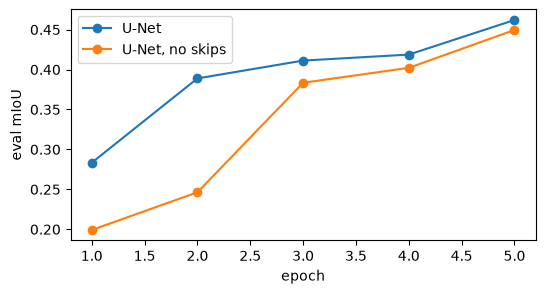

In [10]:
start = time.time()
results["U-Net, no skips"] = train_unet(use_skips=False)
print(f"U-Net without skips: {time.time() - start:.0f} s")

plt.figure(figsize=(6, 3))
for name, (_, history) in results.items():
    plt.plot(range(1, EPOCHS + 1), history, marker="o", label=name)
plt.xlabel("epoch")
plt.ylabel("eval mIoU")
plt.legend()
plt.show()

Both reach mIoU ≈ 0.45 after five epochs; without skips the model is a single-scale decoder from
a 20 × 20 bottleneck, yet loses only about one point. The class table below shows why: wall, sky
and road are large regions whose label is settled by context, and *person*, the one thin, small
class, is missed by both from-scratch models alike.

# 5) SegFormer: Rebuilding the All-MLP Decoder

SegFormer's Mix Transformer encoder emits four feature maps at strides 4, 8, 16, 32 with widths
$C_i$ (32, 64, 160, 256 for B0). The decoder is deliberately tiny:

$$\hat F_i = \text{Up}_{\times 2^{i-1}}\big(W_i F_i\big) \in \mathbb{R}^{D \times \frac{H}{4} \times \frac{W}{4}},
\qquad F = \text{ReLU}\big(\text{BN}(W_f [\hat F_4; \hat F_3; \hat F_2; \hat F_1])\big),
\qquad z = W_c F,$$

with $W_i \in \mathbb{R}^{D \times C_i}$ per-pixel linear maps, $D = 256$, $W_f$ a 1×1 convolution
from $4D$ to $D$ and $W_c$ the 1×1 classifier. It can be this small because self-attention
already gives the deep stages a global receptive field; a CNN encoder with the same decoder does
much worse. Logits come out at 1/4 resolution and are upsampled bilinearly.

The checkpoint below is SegFormer-B0 fine-tuned on ADE20K (all 150 classes, so the eval images
were in its training distribution but not its training set: the ADE20K validation split). Its
150-way prediction is mapped onto the nine kept classes; any other class counts as an error.

In [11]:
processor = SegformerImageProcessor.from_pretrained(MODEL_NAME)
segformer = (
    SegformerForSemanticSegmentation.from_pretrained(MODEL_NAME).to(DEVICE).eval()
)
print(
    f"SegFormer-B0: {sum(p.numel() for p in segformer.parameters()) / 1e6:.1f} M params"
)
print(
    "decoder only: "
    f"{sum(p.numel() for p in segformer.decode_head.parameters()) / 1e6:.2f} M"
)


def mlp_decoder(stages: list[torch.Tensor], head: nn.Module) -> torch.Tensor:
    """Four stage maps (batch_num, C_i, H_i, W_i) -> logits (batch_num, 150, H/4, W/4)."""
    size = stages[0].shape[2:]
    projected = []
    for feat, mlp in zip(stages, head.linear_projections):
        batch_num, _, h, w = feat.shape
        # per-pixel linear: (batch_num, C_i, h, w) -> (batch_num, h*w, D) -> (batch_num, D, h, w)
        x = (
            mlp.proj(feat.flatten(2).transpose(1, 2))
            .transpose(1, 2)
            .reshape(batch_num, -1, h, w)
        )
        projected.append(
            F.interpolate(x, size=size, mode="bilinear", align_corners=False)
        )
    fused = F.relu(head.batch_norm(head.linear_fuse(torch.cat(projected[::-1], dim=1))))
    return head.classifier(fused)


pixel_values = processor(
    images=list(eval_images[:4].permute(0, 2, 3, 1).numpy()), return_tensors="pt"
)["pixel_values"].to(DEVICE)
with torch.no_grad():
    stages = segformer.segformer(pixel_values, output_hidden_states=True).hidden_states
    ours = mlp_decoder(list(stages), segformer.decode_head)
    reference = segformer(pixel_values).logits
print("stage shapes:", [tuple(s.shape[1:]) for s in stages])
print(
    f"logits {tuple(ours.shape)}; max |ours - model| = "
    f"{(ours - reference).abs().max():.1e}"
)

SegFormer-B0: 3.8 M params
decoder only: 0.43 M


stage shapes: [(32, 128, 128), (64, 64, 64), (160, 32, 32), (256, 16, 16)]


logits (4, 150, 128, 128); max |ours - model| = 0.0e+00


In [12]:
# 150 ADE classes -> 0..8, everything else -> NUM_CLASSES (always wrong)
SEG_TO_TASK = torch.full((150,), NUM_CLASSES, dtype=torch.long)
for task_id, ade_id in enumerate(KEPT):
    SEG_TO_TASK[ade_id] = task_id
SEG_TO_TASK = SEG_TO_TASK.to(DEVICE)


def segformer_predict(batch: torch.Tensor) -> torch.Tensor:
    """uint8 (batch_num, 3, H, W) -> task labels (batch_num, H, W)."""
    pixels = processor(
        images=list(batch.permute(0, 2, 3, 1).numpy()), return_tensors="pt"
    )
    logits = segformer(pixels["pixel_values"].to(DEVICE)).logits
    logits = F.interpolate(
        logits, size=batch.shape[2:], mode="bilinear", align_corners=False
    )
    return SEG_TO_TASK[logits.argmax(1)]


start = time.time()
conf_seg = evaluate(segformer_predict, eval_images, eval_masks)
print(f"SegFormer-B0 on {NUM_EVAL} images: {time.time() - start:.0f} s")

print(f"\n{'model':<18} {'mIoU':>6}  " + " ".join(f"{n[:6]:>6}" for n in CLASS_NAMES))
rows = {
    name: evaluate(lambda b, m=m: m(normalise(b)).argmax(1), eval_images, eval_masks)
    for name, (m, _) in results.items()
}
rows["SegFormer-B0"] = conf_seg
for name, conf in rows.items():
    m, iou = miou(conf)
    print(f"{name:<18} {m:6.3f}  " + " ".join(f"{v:6.2f}" for v in iou.tolist()))

SegFormer-B0 on 300 images: 25 s

model                mIoU    wall buildi    sky  floor   tree ceilin   road  grass person


U-Net               0.462    0.45   0.43   0.81   0.48   0.49   0.32   0.61   0.56   0.00
U-Net, no skips     0.450    0.45   0.43   0.81   0.47   0.47   0.30   0.61   0.51   0.00
SegFormer-B0        0.874    0.83   0.84   0.95   0.90   0.84   0.81   0.93   0.90   0.86


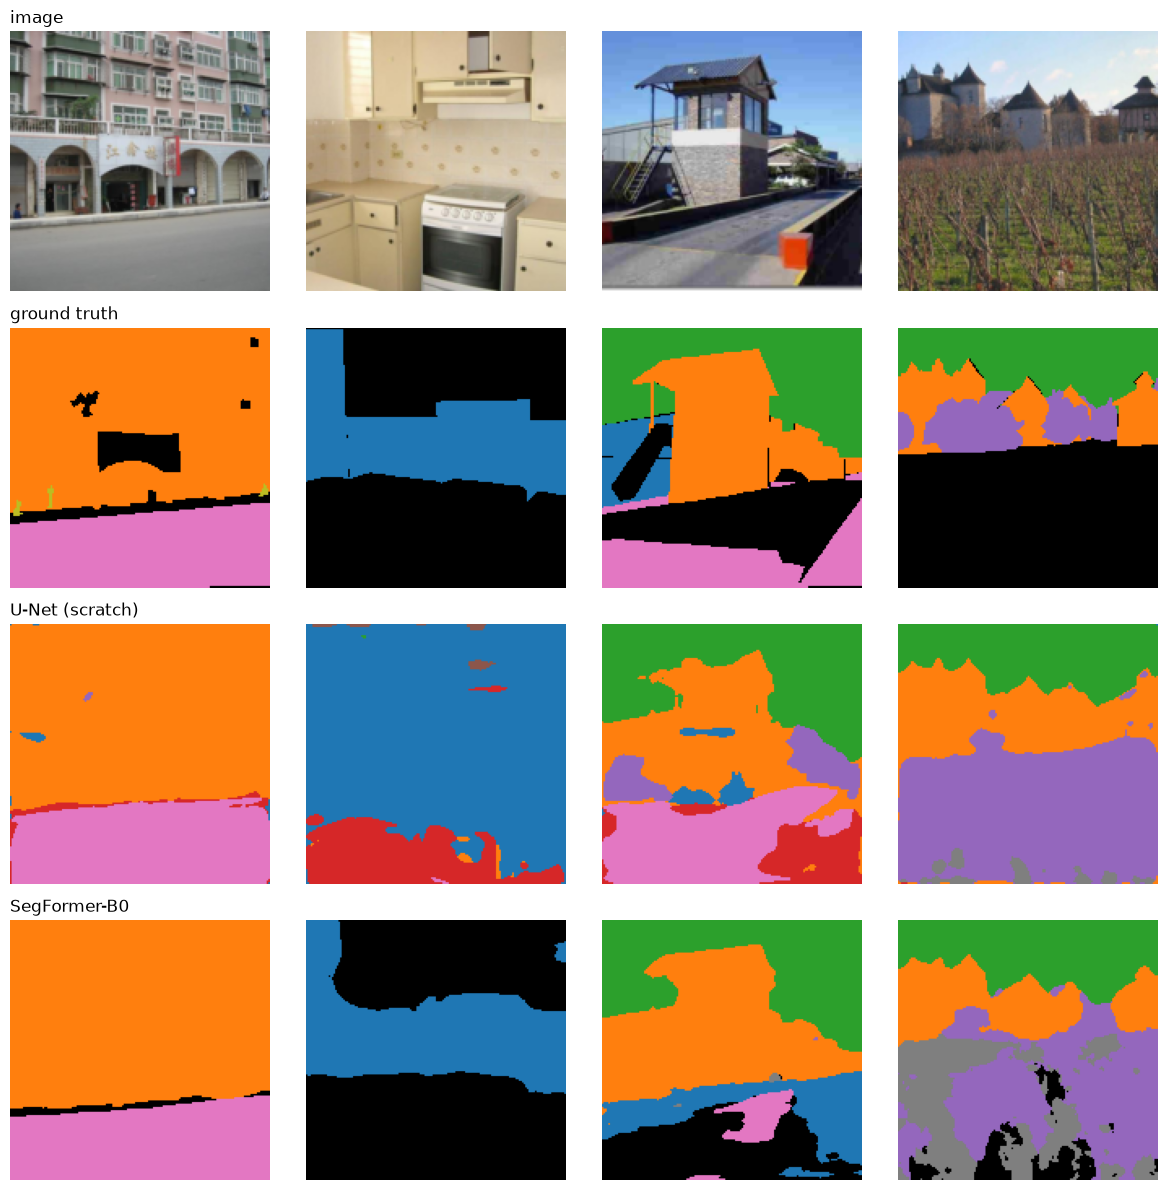

In [13]:
unet = results["U-Net"][0]
batch = eval_images[:4]
with torch.no_grad():
    pred_unet = unet(normalise(batch)).argmax(1).cpu()
    pred_seg = segformer_predict(batch).cpu()
pred_seg[pred_seg == NUM_CLASSES] = IGNORE_INDEX

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for col in range(4):
    panels = [
        batch[col].permute(1, 2, 0),
        show_masks(eval_masks[col]),
        show_masks(pred_unet[col]),
        show_masks(pred_seg[col]),
    ]
    for row, panel in enumerate(panels):
        axes[row, col].imshow(panel)
        axes[row, col].axis("off")
for row, title in enumerate(
    ["image", "ground truth", "U-Net (scratch)", "SegFormer-B0"]
):
    axes[row, 0].set_title(title, loc="left")
plt.tight_layout()
plt.show()

# 6) Practical Notes

- **Loss choice.** Plain cross-entropy optimises pixel accuracy; rare or thin classes (person,
  pole) get few pixels. Class-weighted CE, Dice / Lovász losses (which optimise IoU directly) or
  OHEM (train on the hardest 25% of pixels) trade a little accuracy on large classes for mIoU.
- **Resolution.** Evaluation is normally done at full image resolution with sliding windows or
  multi-scale + flip test-time augmentation; logits are upsampled before the argmax, never the
  argmax itself.
- **Pretraining matters most.** A from-scratch U-Net on 1,500 images learns sky, road and wall
  but not people; production segmenters start from an ImageNet- or self-supervised encoder
  (DINOv2/v3, MiT) and fine-tune on 20k+ images.
- **Where U-Net lives on.** Medical imaging with small datasets and diffusion-model denoisers
  both use the U-Net layout because skip connections preserve exact spatial detail.
- **Beyond per-pixel classes.** Instance and panoptic segmentation predict one mask per object
  query (Mask2Former, SAM), which also handles "things" that touch each other.

# 7) Conclusion

| Model | Params | Trained here | Key mechanism |
|---|---|---|---|
| U-Net | 1.95 M | from scratch, 5 epochs (mIoU 0.46) | encoder–decoder with concatenated skips |
| U-Net without skips | 1.76 M | same (mIoU 0.45) | bottleneck only |
| SegFormer-B0 | 3.8 M | pretrained on ADE20K (mIoU 0.87) | hierarchical attention encoder + all-MLP decoder at 1/4 scale |

- Cross-entropy with an ignore label and a dataset-level confusion matrix are the whole training
  and evaluation protocol for semantic segmentation.
- Skip connections add only about one mIoU point here: which region is sky or road is decided in
  the bottleneck, and mIoU on large stuff classes barely measures boundary sharpness, which is
  what the skips restore. A pretrained hierarchical transformer with a 0.43 M-parameter decoder
  beats both by about 40 points.